In [2]:
import pandas as pd
import scipy.stats
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
import torch.optim as optim
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


# Get responses for an eid

In [2]:
# idx = 23
#
# directory_path = '../Data2'
# all_items = os.listdir(directory_path)
# eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]
# pseudo_response_tensor, condition_matrix, beryl_regions, cosmos_regions = get_eid_response_matrix(
#     eid=eids[idx],
#     directory_path=directory_path,
#     sigma=5,
#     n_steps=100,
#     threshold=0,
#     min_trials_per_condition=50,
#     n_pseudo=25,
#     conditions=['choice'],
#     event="stimOn_times",
#     filter_significant=True,
#     significance_threshold=0.
# )
# category_counts = Counter(cosmos_regions)
# for category, count in category_counts.items():
#     print(f"{category}: {count}")

HB: 719
root: 54
CB: 195
void: 41
HPF: 207
Isocortex: 1
MB: 308


In [3]:
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]
region = 'CP' # Caudoputamen
pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
    eids=eids,
    directory_path=directory_path,
    region=region,
    mapping='Beryl',
    sigma=2,
    n_steps=100,
    threshold=1,
    min_trials_per_condition=50,
    n_pseudo=25,
    conditions=['choice'],
    event="stimOn_times",
    filter_significant=True,
    significance_threshold=0.
)

Aggregating CP responses across 459 EIDs...


Dispatching jobs:  10%|█         | 48/459 [00:17<02:50,  2.41it/s]/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Dispatching jobs: 100%|██████████| 459/459 [03:10<00:00,  2.41it/s]


Max conditions: 2, Common conditions found: [(np.float64(-1.0),), (np.float64(1.0),)]
Total neurons collected: 11270


In [286]:
import torch

def generate_smooth_spectrum_surrogates(data, device="mps", smoothness_factor=0.1):
    """
    Generates surrogates for an (l, k, t, n) tensor that preserve the EXACT
    power spectrum while ensuring the resulting time series remains smooth.
    """
    # 1. Move data to target device
    if not isinstance(data, torch.Tensor):
        X = torch.tensor(data, dtype=torch.float32, device=device)
    else:
        X = data.to(device, dtype=torch.float32)

    l, k, t, n = X.shape

    # 2. Cache original mean and standard deviation along the time axis
    orig_mean = X.mean(dim=2, keepdim=True)
    orig_std = X.std(dim=2, keepdim=True)
    epsilon = 1e-8
    X_normalized = (X - orig_mean) / (orig_std + epsilon)

    # 3. Perform Real FFT along the time dimension (dim=2)
    X_fft = torch.fft.rfft(X_normalized, dim=2)
    num_freqs = X_fft.shape[2]

    # 4. Generate SMOOTH random phases using a native matrix operations approach
    # Step A: Create independent random phase seeds
    raw_noise = torch.randn((l, k, num_freqs, n), device=device)

    # Step B: Build a 1D Gaussian/Smooth smoothing kernel over frequencies
    # This avoids torch.nn.functional.pad entirely
    kernel_width = max(3, int(num_freqs * smoothness_factor))
    freq_indices = torch.arange(num_freqs, dtype=torch.float32, device=device)

    # Create an all-to-all distance matrix for frequency bins
    dist_matrix = torch.abs(freq_indices.unsqueeze(0) - freq_indices.unsqueeze(1))

    # Map distances to a smooth weight window (Gaussian-like curve)
    smooth_weights = torch.exp(- (dist_matrix ** 2) / (2 * (kernel_width / 3) ** 2))
    # Normalize rows so the smoothing doesn't damp the variance scale
    smooth_weights = smooth_weights / (smooth_weights.sum(dim=1, keepdim=True) + epsilon)

    # Step C: Smooth the noise by multiplying across the frequency dimension
    # (l, k, num_freqs, n) -> permute to align frequency dimension for matrix multiplication
    # We matrix multiply the smooth_weights (num_freqs x num_freqs) with the noise matrix
    raw_noise_perm = raw_noise.permute(0, 1, 3, 2) # Shape: (l, k, n, num_freqs)
    smoothed_noise_perm = torch.matmul(raw_noise_perm, smooth_weights.t())
    smoothed_noise = smoothed_noise_perm.permute(0, 1, 3, 2) # Shape back to: (l, k, num_freqs, n)

    # Scale smoothed noise to fit the exact standard [-pi, pi] phase range
    min_val = smoothed_noise.amin(dim=2, keepdim=True)
    max_val = smoothed_noise.amax(dim=2, keepdim=True)
    random_phases = (smoothed_noise - min_val) / (max_val - min_val + epsilon)
    random_phases = (random_phases * 2 * torch.pi) - torch.pi

    # 5. Enforce symmetry constraints for valid real-to-real reconstruction
    random_phases[:, :, 0, :] = 0.0  # DC component (mean)
    if t % 2 == 0:
        random_phases[:, :, -1, :] = 0.0  # Nyquist frequency

    # 6. Apply phase shift (Preserves exact absolute magnitude -> exact power spectrum)
    phase_exp = torch.complex(torch.cos(random_phases), torch.sin(random_phases))
    X_fft_deformed = X_fft * phase_exp

    # 7. Inverse FFT to bring back to the time domain along dim=2
    X_deformed = torch.fft.irfft(X_fft_deformed, n=t, dim=2)

    # 8. Re-normalize to fix floating point artifacts
    X_deformed = (X_deformed - X_deformed.mean(dim=2, keepdim=True)) / (X_deformed.std(dim=2, keepdim=True) + epsilon)

    # 9. Map back to original raw mean and scale
    X_final = (X_deformed * orig_std) + orig_mean

    return X_final

# Example Usage:
# l, k, t, n = 2, 10, 1000, 50
# data = torch.randn(l, k, t, n)
# smooth_surrogates = generate_smooth_spectrum_surrogates(data, device="mps", smoothness_factor=0.1)


In [300]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca

pseudo_response_tensor =np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
pseudo_response_tensor_rand= generate_smooth_spectrum_surrogates(pseudo_response_tensor, device="mps", smoothness_factor=0.1).cpu().numpy()
X_input = iso_ae_preprocessing(pseudo_response_tensor)
X_input_rand = iso_ae_preprocessing(pseudo_response_tensor_rand)


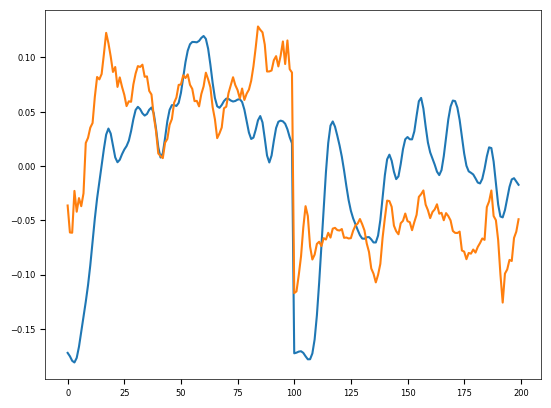

In [304]:
plt.figure()
plt.plot(X_input[11,:])
plt.plot(X_input_rand[11,:])

In [289]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Notebooks'

In [290]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    diff_responses = np.diff(response_tensor_norm, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
    msd = np.mean(np.abs(diff_responses), axis=(0,1))
    return msd

msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))

In [291]:
def get_curvature(model,u,dt,steps):
    """
    Computes curvature for each neuron at each time step and trial.
    Curvature = (h_dot_i)^2 * f''(h_i)
    where h_i is the pre-activation input to neuron i.
    """

    y = model(u,dt,steps)
    input = model.input_layer(u).unsqueeze(1).expand(-1, steps, -1)
    h = model.recurrent_layer(y) + input

    # 3. Compute f''(h) for softplus
    beta = model.beta
    f_prime = torch.sigmoid(beta * h)
    f_double_prime = beta * f_prime * (1 - f_prime)

    # 4. Compute y_dot analytically
    y_dot = model.alpha*(-y + model.activation(h))

    # 5. Compute h_dot analytically
    h_dot = torch.matmul(y_dot, model.recurrent_layer.weight.t())

    # 6. Compute curvature = (h_dot)^2 * f''(h)
    curvature = (h_dot**2) * f_double_prime

    return curvature.detach().cpu().numpy(),h.detach().cpu().numpy(),y_dot.detach().cpu().numpy()



In [292]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Notebooks'

In [293]:

# Define and fit RNN
class RNN(torch.nn.Module):
    def __init__(self, n, input_dim,beta,bias):
        super(RNN, self).__init__()

        self.n = n
        self.input_dim = input_dim
        self.beta = beta
        self.bias = bias
        self.activation = torch.nn.Softplus(beta =self.beta)
        # Hidden dynamics
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=self.bias, std=0)
        self.recurrent_layer.bias.requires_grad = True

        self.input_layer = nn.Linear(self.input_dim, self.n, bias=False)
        self.alpha = nn.Parameter(.1*torch.ones(n))
    def forward(self, u, dt, steps):
        batch_size = u.shape[0]
        states = torch.zeros(batch_size, 1, self.n, device=device)
        for i in range(steps - 1):
            state_new = (1 - self.alpha *dt) * states[:, i, :] + self.alpha *dt * (
                self.activation(self.recurrent_layer(states[:, i, :]) + self.input_layer(u)))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)
        return states

#net = RNN(n=X_input.shape[0], input_dim=1, beta=2,bias = 1)

# 2. Deserialize the saved state_dict file with strict security boundaries
# Using weights_only=True blocks arbitrary code execution vulnerabilities during unpickling.
net = torch.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/CP_net.pth',weights_only=False,map_location=torch.device('cpu'))

# 3. Load the parameter dictionary into your active model instance
n_neurons = pseudo_response_tensor.shape[3]
bias = 2
beta = 2
lr = .0002
dt = 1
steps = 100
active_lambda = 0.01
device = 'cpu'
# net = RNN(n=n_neurons, input_dim=1, beta=beta,bias = bias).to(device)
#
u = torch.FloatTensor(np.linspace(-1, 1, 2)).to(device)
# optimizer = optim.Adam(net.parameters(), lr=lr)
# criterion = nn.MSELoss()
#
# for epoch in range(10000):
#     optimizer.zero_grad()
#     x = net(u.unsqueeze(1),dt,steps)
#     mean_activities = x.mean(dim=(0, 1)) # Mean activity per neuron
#     activity_penalty = mean_activities.std()
#    # x,_ = compute_group_averages(x, u.unsqueeze(1))
#     x = x.reshape(-1, x.shape[2]).T
#     activity_penalty = torch.std(torch.mean(x,dim=1)) + torch.std(torch.std(x,dim=1))
#     x = (x - torch.mean(x,dim = 1,keepdim=True))/torch.std(x,dim = 1,keepdim = True)
#     loss = criterion(torch.FloatTensor(X_input), x) + active_lambda*activity_penalty
#     loss.backward()
#     optimizer.step()
#     if epoch % 100 == 0:
#         print(f"Epoch {epoch}: Loss = {loss.item():.4f}")


In [294]:
net.recurrent_layer.bias

Parameter containing:
tensor([2.0578, 2.0834, 2.0193,  ..., 1.9896, 2.0173, 1.9918],
       requires_grad=True)

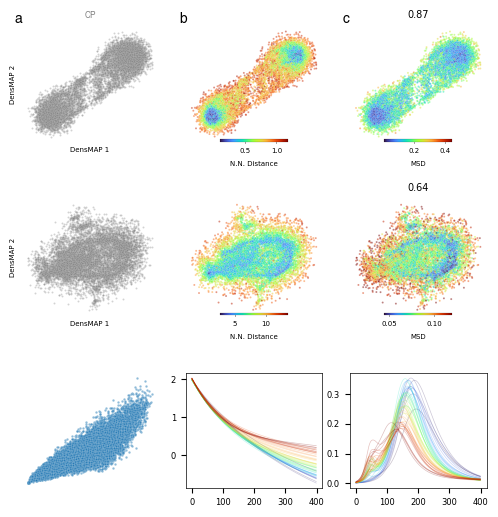

In [295]:
# Summary plot

fig = plt.figure(figsize=(6, 6))
gs = gridspec.GridSpec(3, 3,hspace = .5)

# First row
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])
ax3 = plt.subplot(gs[0,2])
# Second row
ax4 = plt.subplot(gs[1,0])
ax5 = plt.subplot(gs[1,1])
ax6 = plt.subplot(gs[1,2])
# Third row
ax7 = plt.subplot(gs[2,0])
ax8 = plt.subplot(gs[2,1])
ax9 = plt.subplot(gs[2,2])

# First row
z_neurons_cp = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_input)
loc_density_data = get_density_proxy(X_input, k=50).numpy()
# Gray
sns.scatterplot(x=z_neurons_cp[:, 0], y=z_neurons_cp[:, 1], color='gray', s=2, alpha=.35,ax=ax1)
# NN Distance
sns.scatterplot(x=z_neurons_cp[:, 0], y=z_neurons_cp[:, 1], c=loc_density_data,cmap  = 'turbo', s=2, alpha=.5,ax=ax2)
cax = inset_axes(
        ax2, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(loc_density_data.min(), loc_density_data.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
# MSD
vmin_msd, vmax_msd = np.percentile(msd_data, [1, 99])
range_msd = vmax_msd - vmin_msd
vmin_msd -= 0.1 * range_msd
vmax_msd += 0.1 * range_msd
sns.scatterplot(x=z_neurons_cp[:, 0], y=z_neurons_cp[:, 1], c=msd_data,cmap='turbo', s=2, alpha=.5,ax=ax3,vmin=vmin_msd,vmax=np.max(msd_data)+.1 )
cax = inset_axes(
        ax3, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd_data.min(), msd_data.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

correlation,_ = scipy.stats.spearmanr(loc_density_data, msd_data)
ax3.set_title(f"{correlation:.2f}",fontsize = 7)


# Second row
X_rnn = net(u.unsqueeze(1),dt,steps)
X_rnn = (X_rnn - torch.mean(X_rnn,dim = (0,1),keepdim=True))/torch.std(X_rnn,dim = (0,1),keepdim = True)
msd_rnn = torch.mean(torch.abs(torch.diff(X_rnn,dim=1)), dim = (0,1)).detach().numpy()
#zddot = compute_neuron_derivatives(X_rnn.detach().numpy(),1)
#msd_rnn = np.mean(np.abs(zddot),axis=(0,1))
X_rnn = X_rnn.reshape(-1, X_rnn.shape[2]).T
#msd_rnn = fast_approximate_mean(X_rnn.detach().numpy(), msd_rnn, k=5).squeeze()
/
num_percentiles = 50
labels, cut_edges = pd.qcut(msd_rnn, q=num_percentiles, retbins=True, labels=False)
df = pd.DataFrame({'value': msd_rnn, 'group': labels})
group_means = df.groupby('group')['value'].mean()
df['replaced_value'] = df['group'].map(group_means)
msd_rnn = np.array(df['replaced_value'].tolist())

curvature, h,ydot = get_curvature(net, u.unsqueeze(1), .01, 400)
peak_h = np.mean(h[:,200,:], axis = 0)

df = pd.DataFrame({'value': peak_h, 'group': labels})
group_means = df.groupby('group')['value'].mean()
df['replaced_value'] = df['group'].map(group_means)
peak_h = np.array(df['replaced_value'].tolist())

#z_neurons = umap.UMAP(densmap=True,dens_lambda=2,n_neighbors=500).fit_transform(X_rnn.detach())
loc_density_rnn = get_density_proxy(X_rnn.detach(), k=50).numpy()
# Gray
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=2, alpha=.35,ax=ax4)
# NN Distance
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=loc_density_rnn,cmap  = 'turbo', s=2, alpha=.5,ax=ax5)
cax = inset_axes(
        ax5, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(loc_density_rnn.min(), loc_density_rnn.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
# MSD
vmin_msd, vmax_msd = np.percentile(msd_rnn, [0, 100])
range_msd = vmax_msd - vmin_msd
vmin_msd -= 0.1 * range_msd
vmax_msd += 0.2 * range_msd
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd_rnn,cmap='turbo', s=2, alpha=.5,ax=ax6)
cax = inset_axes(
        ax6, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd_rnn.min(), msd_rnn.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

correlation,_ = scipy.stats.spearmanr(loc_density_rnn, msd_rnn)
ax6.set_title(f"{correlation:.2f}",fontsize = 7)

# Third row
sns.scatterplot(x =loc_density_data,y = msd_data,ax= ax7,s = 3, alpha = .5 )
#sns.scatterplot(x =loc_density_rnn,y = msd_rnn.detach(),ax= ax8 ,s =3, alpha = .5)


#y = net(u.unsqueeze(1),dt,steps)

n_groups = 50
msd_sorted_indices = np.argsort(msd_rnn)
group_size = n_neurons // n_groups
groups = [msd_sorted_indices[i * group_size:(i + 1) * group_size] for i in range(n_groups)]
if n_neurons % n_groups != 0:
    groups[-1] = np.concatenate([groups[-1], msd_sorted_indices[n_groups * group_size:]])



cmap = plt.get_cmap('turbo')
colors = [cmap(i / (n_groups - 1)) for i in range(n_groups)] if n_groups > 1 else [cmap(0.5)]

for g_idx, group in enumerate(groups):
    color = colors[g_idx]
    # Plot individual neurons
    # for i in group:
    #     plt.plot(curvature[1, :, i], color=color, alpha=0.1, lw=1)
    #
    # Plot mean within group
    group_mean = np.mean(curvature[:, :, group], axis=(0,2))
    ax9.plot(group_mean, color=color, alpha=0.25, lw=.5, label=f'Group {g_idx+1}')

    group_mean = np.mean(h[:, :, group], axis=(0,2))
    ax8.plot(group_mean, color=color, alpha=0.25, lw=.5, label=f'Group {g_idx+1}')


# 4. Global figure customizations
#fig.suptitle("Main Title for All 5 Subplots", fontsize=18, fontweight="bold", y=1.05)

# Automatically adjusts subplot parameters so that the labels don't overlap
for ax in [ax1,ax2,ax3,ax4,ax5,ax6,ax7]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')


ax1.set_xlabel('DensMAP 1',fontsize = 5)
ax1.set_ylabel('DensMAP 2',fontsize = 5)
ax4.set_xlabel('DensMAP 1',fontsize = 5)
ax4.set_ylabel('DensMAP 2',fontsize = 5)
# Figure labels
ax1.text(-0.05, 1., 'a', transform=ax1.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax2.text(-0.05, 1, 'b', transform=ax2.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax3.text(-0.05, 1, 'c', transform=ax3.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')

# Subfigure titles
ax1.set_title('CP',fontsize = 6,fontname = 'Helvetica',alpha = .5)

# axes[3].set_title('Rotation 1',fontsize = 6,fontname = 'Helvetica')
# 5. Display or save the plot
#plt.tight_layout()
plt.savefig("CPRotations.png", bbox_inches='tight', dpi=300)



<Axes: xlabel='None', ylabel='Count'>

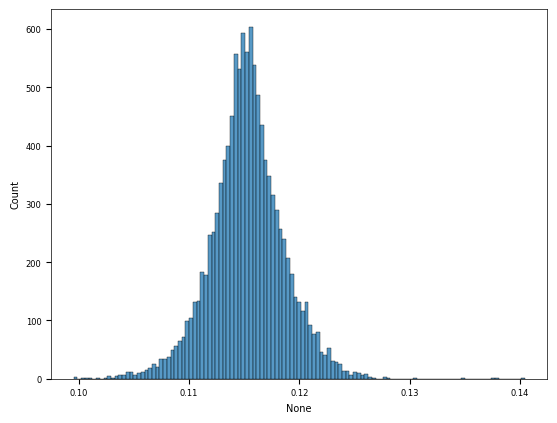

In [148]:
plt.figure()
x = net(u.unsqueeze(1),dt,steps)
sns.histplot(x = torch.std(x, dim = (0,1)).detach())

In [187]:
def compute_neuron_derivatives(y,dt = 1):
    y_dot = np.gradient(y,dt,axis=1)
    y_ddot = np.gradient(y_dot,dt,axis=1)
    return y_dot + y_ddot

x = net(u.unsqueeze(1),dt,steps)

zddot = compute_neuron_derivatives(x.detach().numpy(),1)
curvature, h,ydot = get_curvature(net, u.unsqueeze(1), 1, 100)

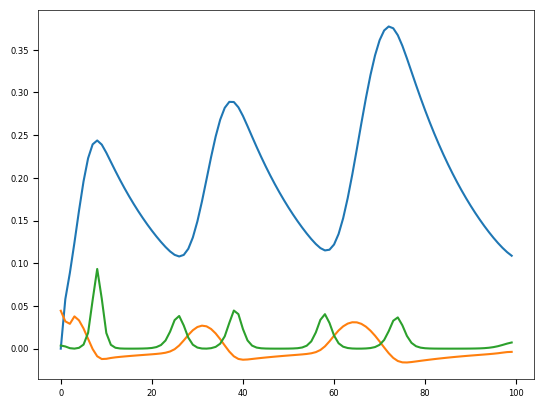

In [171]:
plt.figure()
neuron = msd_sorted_indices[-10]
trial =1
plt.plot(x[trial,:,neuron].detach())
plt.plot(zddot[trial,:,neuron])
plt.plot(curvature[trial,:,neuron])

In [ ]:
m

MLP Epoch 0: Loss = 13.7102
MLP Epoch 500: Loss = 0.0351
MLP Epoch 1000: Loss = 0.0161
MLP Epoch 1500: Loss = 0.0123
MLP Epoch 2000: Loss = 0.0115
MLP Epoch 2500: Loss = 0.0102
MLP Epoch 3000: Loss = 0.0065
MLP Epoch 3500: Loss = 0.0051
MLP Epoch 4000: Loss = 0.0087
MLP Epoch 4500: Loss = 0.0060


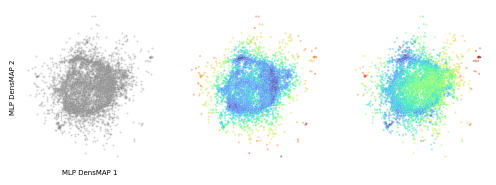

In [128]:
# Train MLP to reproduce DensMAP transformation
class DensMAPRegressor(nn.Module):
    def __init__(self, input_dim):
        super(DensMAPRegressor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.net(x)

# Prepare data
# X_rnn was (conditions, steps, neurons)
X_rnn_orig = net(u.unsqueeze(1).to(device), dt, steps)
X_rnn_orig_norm = (X_rnn_orig - torch.mean(X_rnn_orig, dim=(0, 1), keepdim=True)) / (torch.std(X_rnn_orig, dim=(0, 1), keepdim=True) + 1e-8)
X_train = X_rnn_orig_norm.reshape(-1, X_rnn_orig_norm.shape[2]).T.detach()
y_train = torch.FloatTensor(z_neurons).to(device)

# Initialize model, loss, optimizer
densmap_mlp = DensMAPRegressor(input_dim=X_train.shape[1]).to(device)
mlp_criterion = nn.MSELoss()
mlp_optimizer = optim.Adam(densmap_mlp.parameters(), lr=0.001)

# Training loop
epochs = 5000
for epoch in range(epochs):
    mlp_optimizer.zero_grad()
    predictions = densmap_mlp(X_train)
    loss = mlp_criterion(predictions, y_train)
    loss.backward()
    mlp_optimizer.step()
    if epoch % 500 == 0:
        print(f"MLP Epoch {epoch}: Loss = {loss.item():.4f}")

# Verify on RNN data
with torch.no_grad():
    z_neurons_mlp = densmap_mlp(X_train).cpu().numpy()

# Regenerate second row of summary plot with MLP projection
fig_mlp, axes_mlp = plt.subplots(1, 3, figsize=(6, 2))
ax4_mlp, ax5_mlp, ax6_mlp = axes_mlp

# Gray
sns.scatterplot(x=z_neurons_mlp[:, 0], y=z_neurons_mlp[:, 1], color='gray', s=2, alpha=.35, ax=ax4_mlp)
# NN Distance
sns.scatterplot(x=z_neurons_mlp[:, 0], y=z_neurons_mlp[:, 1], c=loc_density_rnn, cmap='turbo', s=2, alpha=.5, ax=ax5_mlp)
# MSD
sns.scatterplot(x=z_neurons_mlp[:, 0], y=z_neurons_mlp[:, 1], c=msd_rnn.detach().cpu().numpy(), cmap='turbo', s=2, alpha=.5, ax=ax6_mlp)

for ax in axes_mlp:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

ax4_mlp.set_xlabel('MLP DensMAP 1', fontsize=5)
ax4_mlp.set_ylabel('MLP DensMAP 2', fontsize=5)
plt.show()


Retrain Epoch 0: Loss = 0.0683, Scree = 0.0000, MSD_pen = 0.0683
Retrain Epoch 10: Loss = 0.0411, Scree = 0.0001, MSD_pen = 0.0403
Retrain Epoch 20: Loss = 0.0292, Scree = 0.0002, MSD_pen = 0.0276
Retrain Epoch 30: Loss = 0.0249, Scree = 0.0002, MSD_pen = 0.0231
Retrain Epoch 40: Loss = 0.0225, Scree = 0.0003, MSD_pen = 0.0200
Retrain Epoch 49: Loss = 0.0218, Scree = 0.0003, MSD_pen = 0.0190


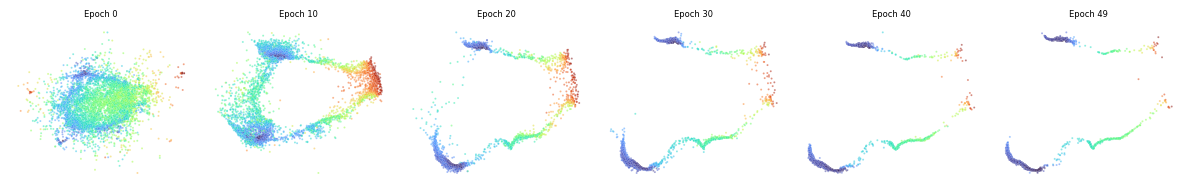

In [131]:
import copy

# 1. Create a copy of the trained RNN
net_retrain = copy.deepcopy(net)
optimizer_retrain = optim.Adam(net_retrain.parameters(), lr=0.0001)

# 2. Calculate original scree plot
with torch.no_grad():
    X_orig = net(u.unsqueeze(1).to(device), dt, steps)
    X_orig = (X_orig - torch.mean(X_orig, dim=(0, 1), keepdim=True)) / (torch.std(X_orig, dim=(0, 1), keepdim=True) + 1e-8)
    X_orig_mat = X_orig.reshape(-1, X_orig.shape[2]).T # (neurons, time*conds)
    _, S_orig, _ = torch.linalg.svd(X_orig_mat, full_matrices=False)
    S_orig = S_orig / torch.sum(S_orig) # Normalize

# 3. Retraining parameters
retrain_epochs = 50
k = 10 # Frequency of plotting
saved_projections = []
saved_msd = []

# 4. Retraining loop
for epoch in range(retrain_epochs):
    optimizer_retrain.zero_grad()
    
    # Forward pass
    X_curr = net_retrain(u.unsqueeze(1).to(device), dt, steps)
    
    # Calculate MSD
    X_curr_norm = (X_curr - torch.mean(X_curr, dim=(0, 1), keepdim=True)) / (torch.std(X_curr, dim=(0, 1), keepdim=True) + 1e-8)
    msd_curr = torch.mean(torch.abs(torch.diff(X_curr_norm, dim=1)), dim=(0, 1))
    
    # MSD penalty for top 50%
    threshold = torch.median(msd_curr)
    msd_penalty = torch.mean(msd_curr[msd_curr > threshold])
    
    # Scree plot preservation
    X_curr_mat = X_curr_norm.reshape(-1, X_curr_norm.shape[2]).T
    _, S_curr, _ = torch.linalg.svd(X_curr_mat, full_matrices=False)
    S_curr = S_curr / torch.sum(S_curr)
    scree_loss = nn.MSELoss()(S_curr, S_orig)
    
    # Total loss
    total_loss = 10 * scree_loss + msd_penalty
    
    total_loss.backward()
    optimizer_retrain.step()
    
    if epoch % k == 0 or epoch == retrain_epochs - 1:
        print(f"Retrain Epoch {epoch}: Loss = {total_loss.item():.4f}, Scree = {scree_loss.item():.4f}, MSD_pen = {msd_penalty.item():.4f}")
        with torch.no_grad():
            # Project using densmap_mlp
            # densmap_mlp expects (neurons, time*conds) as input during training based on X_train
            z_proj = densmap_mlp(X_curr_mat).cpu().numpy()
            saved_projections.append(z_proj)
            saved_msd.append(msd_curr.detach().cpu().numpy())




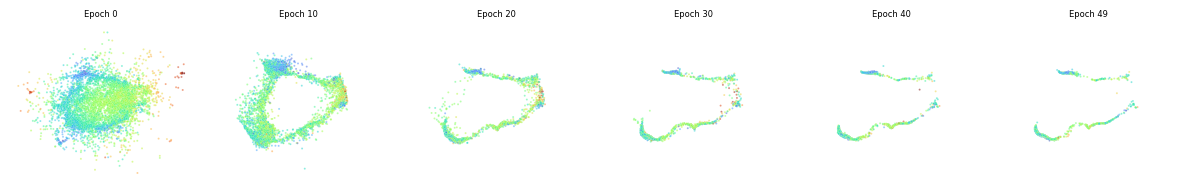

In [132]:
# 5. Plot the saved projections in a row
n_plots = len(saved_projections)
fig_retrain, axes_retrain = plt.subplots(1, n_plots, figsize=(2 * n_plots, 2))

# Calculate global limits for consistent scaling
all_projections = np.concatenate(saved_projections, axis=0)
x_min, x_max = all_projections[:, 0].min(), all_projections[:, 0].max()
y_min, y_max = all_projections[:, 1].min(), all_projections[:, 1].max()

# Add a small margin to axis limits
x_range = x_max - x_min
y_range = y_max - y_min
x_min -= 0.05 * x_range
x_max += 0.05 * x_range
y_min -= 0.05 * y_range
y_max += 0.05 * y_range

all_msd = np.concatenate(saved_msd)
vmin_msd_global = all_msd.min()
vmax_msd_global = all_msd.max()

for i in range(n_plots):
    ax = axes_retrain[i]
    sns.scatterplot(x=saved_projections[i][:, 0], y=saved_projections[i][:, 1],
                    c=saved_msd[0], cmap='turbo', s=2, alpha=.5, ax=ax,
                    vmin=vmin_msd_global, vmax=vmax_msd_global)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"Epoch {i*k if i < n_plots-1 else retrain_epochs-1}", fontsize=6)

plt.tight_layout()
plt.show()

Retrain Epoch 0: Loss = 0.0034, Scree = 0.0003, MSD_pen = 0.0000
Retrain Epoch 10: Loss = 0.0002, Scree = 0.0000, MSD_pen = 0.0001
Retrain Epoch 20: Loss = 0.0002, Scree = 0.0000, MSD_pen = 0.0001
Retrain Epoch 30: Loss = 0.0001, Scree = 0.0000, MSD_pen = 0.0001
Retrain Epoch 40: Loss = 0.0001, Scree = 0.0000, MSD_pen = 0.0000
Retrain Epoch 49: Loss = 0.0001, Scree = 0.0000, MSD_pen = 0.0000


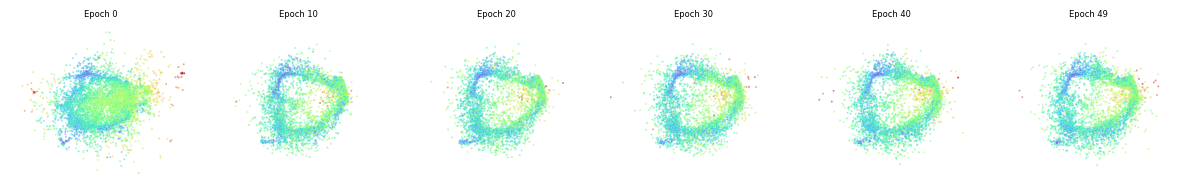

In [137]:
# Fix msd, penalize variance above dimension n
import copy

# 1. Create a copy of the trained RNN
net_retrain = copy.deepcopy(net)
optimizer_retrain = optim.Adam(net_retrain.parameters(), lr=0.0001)

# 2. Calculate original scree plot
with torch.no_grad():
    X_orig = net(u.unsqueeze(1).to(device), dt, steps)
    X_orig = (X_orig - torch.mean(X_orig, dim=(0, 1), keepdim=True)) / (torch.std(X_orig, dim=(0, 1), keepdim=True) + 1e-8)
    X_orig_mat = X_orig.reshape(-1, X_orig.shape[2]).T # (neurons, time*conds)
    _, S_orig, _ = torch.linalg.svd(X_orig_mat, full_matrices=False)
    S_orig = S_orig / torch.sum(S_orig) # Normalize

# 3. Retraining parameters
retrain_epochs = 50
k = 10 # Frequency of plotting
saved_projections = []
saved_msd = []

# 4. Retraining loop
for epoch in range(retrain_epochs):
    optimizer_retrain.zero_grad()

    # Forward pass
    X_curr = net_retrain(u.unsqueeze(1).to(device), dt, steps)

    # Calculate MSD
    X_curr_norm = (X_curr - torch.mean(X_curr, dim=(0, 1), keepdim=True)) / (torch.std(X_curr, dim=(0, 1), keepdim=True) + 1e-8)
    msd_curr = torch.mean(torch.abs(torch.diff(X_curr_norm, dim=1)), dim=(0, 1))

    # MSD penalty for top 50%
    threshold = torch.median(msd_curr)
    msd_penalty = nn.MSELoss()(msd_curr, msd_rnn.detach())

    # Scree plot preservation
    X_curr_mat = X_curr_norm.reshape(-1, X_curr_norm.shape[2]).T
    _, S_curr, _ = torch.linalg.svd(X_curr_mat, full_matrices=False)
    S_curr = S_curr / torch.sum(S_curr)
    scree_loss = torch.sum(S_curr[25:])

    # Total loss
    total_loss = 10 * scree_loss + msd_penalty

    total_loss.backward()
    optimizer_retrain.step()

    if epoch % k == 0 or epoch == retrain_epochs - 1:
        print(f"Retrain Epoch {epoch}: Loss = {total_loss.item():.4f}, Scree = {scree_loss.item():.4f}, MSD_pen = {msd_penalty.item():.4f}")
        with torch.no_grad():
            # Project using densmap_mlp
            # densmap_mlp expects (neurons, time*conds) as input during training based on X_train
            z_proj = densmap_mlp(X_curr_mat).cpu().numpy()
            saved_projections.append(z_proj)
            saved_msd.append(msd_curr.detach().cpu().numpy())




# 5. Plot the saved projections in a row
n_plots = len(saved_projections)
fig_retrain, axes_retrain = plt.subplots(1, n_plots, figsize=(2 * n_plots, 2))

# Calculate global limits for consistent scaling
all_projections = np.concatenate(saved_projections, axis=0)
x_min, x_max = all_projections[:, 0].min(), all_projections[:, 0].max()
y_min, y_max = all_projections[:, 1].min(), all_projections[:, 1].max()

# Add a small margin to axis limits
x_range = x_max - x_min
y_range = y_max - y_min
x_min -= 0.05 * x_range
x_max += 0.05 * x_range
y_min -= 0.05 * y_range
y_max += 0.05 * y_range

all_msd = np.concatenate(saved_msd)
vmin_msd_global = all_msd.min()
vmax_msd_global = all_msd.max()

for i in range(n_plots):
    ax = axes_retrain[i]
    sns.scatterplot(x=saved_projections[i][:, 0], y=saved_projections[i][:, 1],
                    c=saved_msd[0], cmap='turbo', s=2, alpha=.5, ax=ax,
                    vmin=vmin_msd_global, vmax=vmax_msd_global)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"Epoch {i*k if i < n_plots-1 else retrain_epochs-1}", fontsize=6)

plt.tight_layout()
plt.show()

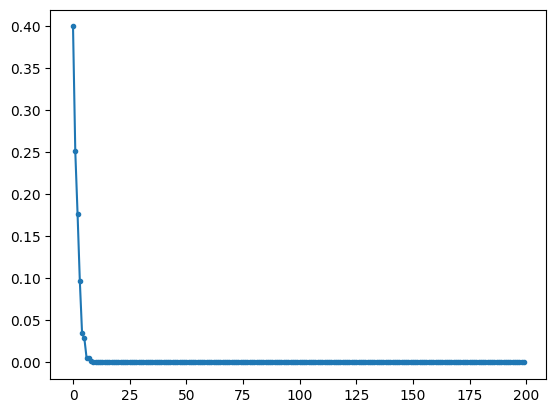

In [136]:
plt.figure()
plt.plot(S_curr.detach(),marker='.')

In [ ]:
def decay_constant(h):
    '''
    :param h: time series of synaptic input
    :return: decay constant of log exponential fit
    '''


In [ ]:
import numpy as np
from scipy.optimize import curve_fit

def get_decay_constant_dt(h, dt):
    """Fits an exponential decay curve to data using a fixed time step.

    Parameters:
    y (array-like): Data array.
    dt (float): Time step interval between data points.

    Returns:
    float: The decay constant (lambda).
    """
    # Create the time array based on data length and dt
    t = np.arange(len(h)) * dt

    # Define the decay function: y = A * exp(-lambda * t)
    def exp_decay(time, a, lam):
        return a * np.exp(-lam * time)

    # Estimate starting parameters: peak value and decay rate guess
    initial_guess = [h[0], 1.0 / (len(h) * dt)]

    # Perform curve fitting
    popt, _ = curve_fit(exp_decay, t, h, p0=initial_guess)

    return popt[1]


In [8]:
from sklearn.neighbors import NearestNeighbors

def mean_of_k_nearest_neighbors(X, y, k):
    """Calculates the mean of y over the k-nearest neighbors in X for each sample.

    Parameters:
    X (numpy.ndarray): Input feature array of shape (n, d).
    y (numpy.ndarray): Target array of shape (n, 1).
    k (int): Number of nearest neighbors to average.

    Returns:
    numpy.ndarray: Array of shape (n, 1) containing the mean y value for each sample's neighbors.
    """
    # Initialize and fit the nearest neighbors model
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X)

    # Find the indices of the k nearest neighbors for each point
    # indices will have a shape of (n, k)
    _, indices = nn.kneighbors(X)

    # Map the indices to the corresponding y values and calculate the mean along the neighbor axis
    # y[indices] creates a shape of (n, k, 1)
    mean_y = np.mean(y[indices], axis=1)

    return mean_y

In [201]:
import numpy as np

def generate_tensor_by_joint_mean(k, t, n, D_list, max_iter=3000, lr=0.2, tol=1e-5):
    # 1. Base verification
    D = np.array(D_list).flatten()
    if len(D) != n:
        raise ValueError(f"D must have exactly n ({n}) elements. Found {len(D)}.")

    # max_possible_D = 2.0 / np.sqrt(t)
    # if np.any(D > max_possible_D) or np.any(D < 0):
    #     raise ValueError(f"Target values in D must be between 0 and {max_possible_D:.4f} for t={t}.")

    # 2. Initialize our random tensor of target shape (k, t, n)
    X = np.random.normal(size=(k, t, n))

    # 3. Vectorized Gradient Descent Optimization Loop
    for _ in range(max_iter):
        # Enforce unit length strictly along the t dimension (axis=1)
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms = np.where(norms == 0, 1e-8, norms)
        X_normalized = X / norms

        # Calculate current absolute differences and their mean across axes 0 and 1
        abs_diffs = np.abs(np.diff(X_normalized, axis=1))
        current_means = np.mean(abs_diffs, axis=(0, 1)) # shape: (n,)

        # Stop optimization if the maximum absolute error falls below threshold
        if np.max(np.abs(current_means - D)) < tol:
            break

        # Parallelized numerical gradient calculation
        grad = np.zeros_like(X)
        eps = 1e-6

        # We perturb each time slice 'col' across all k and n matrices simultaneously
        for col in range(t):
            # Positive modification slice
            X_plus = X.copy()
            X_plus[:, col, :] += eps
            X_p_norm = X_plus / np.linalg.norm(X_plus, axis=1, keepdims=True)
            means_plus = np.mean(np.abs(np.diff(X_p_norm, axis=1)), axis=(0, 1))
            loss_plus = np.sum((means_plus - D) ** 2)

            # Negative modification slice
            X_minus = X.copy()
            X_minus[:, col, :] -= eps
            X_m_norm = X_minus / np.linalg.norm(X_minus, axis=1, keepdims=True)
            means_minus = np.mean(np.abs(np.diff(X_m_norm, axis=1)), axis=(0, 1))
            loss_minus = np.sum((means_minus - D) ** 2)

            # Compute partial derivative slope for this entire time plane
            grad[:, col, :] = (loss_plus - loss_minus) / (2 * eps)

        # Update tensor configuration
        X -= lr * grad

    # 4. Final normalization pass to secure exact unit bounds
    final_norms = np.linalg.norm(X, axis=1, keepdims=True)
    return X / final_norms

# --- Example Parameters ---
responses = np.mean(pseudo_response_tensor,axis=0)
k, t, n = responses.shape
D_targets = list(msd_data) # Exactly matches length n

result_tensor = generate_tensor_by_joint_mean(k, t, n, D_targets)

# --- Verification ---
print("Output Array Shape:", result_tensor.shape)

# Step A: Norm check along the t-axis (should be exactly 1.0)
norms_t = np.linalg.norm(result_tensor, axis=1)
print("\nVerified Unit Norms along t dimension (All entries must be 1.0):")
print(norms_t)

# Step B: Difference computation matching your validation requirement
absolute_differences = np.abs(np.diff(result_tensor, axis=1))
joint_mean_output = np.mean(absolute_differences, axis=(0, 1))

print("\nVerified Shared Absolute Means across k and t-1 dimensions (Should match D):")
print("Target D Array: ", D_targets)
print("Computed Array: ", joint_mean_output)


KeyboardInterrupt: 

In [194]:
torch.linalg.norm(torch.FloatTensor(X_input), dim=1)

tensor([1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000])

In [197]:
responses.shape

(2, 100, 11268)

In [216]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Define dimensions
k, t, n = responses.shape


# 2. Mock function that takes a (k x t x n) tensor and outputs an (n) tensor
def my_function(x):
    z = (x - torch.mean(x, axis=(0, 1), keepdims=True)) / (torch.std(x, axis=(0, 1), keepdims=True) + 1e-8)
    diff_responses = torch.diff(z, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
    msd = torch.mean(torch.abs(diff_responses), axis=(0,1))
    return msd
# 3. Initialize target tensor and input tensor (marked for gradient tracking)
target_output = torch.FloatTensor(msd_data)
# This is the tensor we will optimize:
input_tensor = torch.randn(k, t, n, requires_grad=True)

# 4. Set up the loss function and optimizer
criterion = nn.MSELoss()
# Pass only the input_tensor to the optimizer
optimizer = optim.Adam([input_tensor], lr=0.01)

# 5. Optimization Loop
epochs = 3000
for epoch in range(epochs):
    # Zero out gradients to prevent accumulation
    optimizer.zero_grad()

    # Forward pass
    output = my_function(input_tensor)

    # Calculate loss
    loss = criterion(output, target_output)

    # Backward pass to compute gradients
    loss.backward()

    # Update input_tensor based on gradients
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

print("Optimization complete.")


Epoch [100/3000], Loss: 0.1704
Epoch [200/3000], Loss: 0.0554
Epoch [300/3000], Loss: 0.0269
Epoch [400/3000], Loss: 0.0156
Epoch [500/3000], Loss: 0.0099
Epoch [600/3000], Loss: 0.0067
Epoch [700/3000], Loss: 0.0047
Epoch [800/3000], Loss: 0.0034
Epoch [900/3000], Loss: 0.0025
Epoch [1000/3000], Loss: 0.0019
Epoch [1100/3000], Loss: 0.0014
Epoch [1200/3000], Loss: 0.0011
Epoch [1300/3000], Loss: 0.0009
Epoch [1400/3000], Loss: 0.0007
Epoch [1500/3000], Loss: 0.0006
Epoch [1600/3000], Loss: 0.0005
Epoch [1700/3000], Loss: 0.0004
Epoch [1800/3000], Loss: 0.0003
Epoch [1900/3000], Loss: 0.0003
Epoch [2000/3000], Loss: 0.0002
Epoch [2100/3000], Loss: 0.0002
Epoch [2200/3000], Loss: 0.0002
Epoch [2300/3000], Loss: 0.0001
Epoch [2400/3000], Loss: 0.0001
Epoch [2500/3000], Loss: 0.0001
Epoch [2600/3000], Loss: 0.0001
Epoch [2700/3000], Loss: 0.0001
Epoch [2800/3000], Loss: 0.0001
Epoch [2900/3000], Loss: 0.0000
Epoch [3000/3000], Loss: 0.0000
Optimization complete.


In [217]:
response_tensor = input_tensor.detach().numpy()
# Z-score and reshape
response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
X_transposed = response_matrix.T
# Scale each row (neuron) to unit length
row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
X_pre_pca = X_transposed / (row_norms + 1e-8)

In [218]:
X_pre_pca.shape

(11268, 200)

<Axes: xlabel='None'>

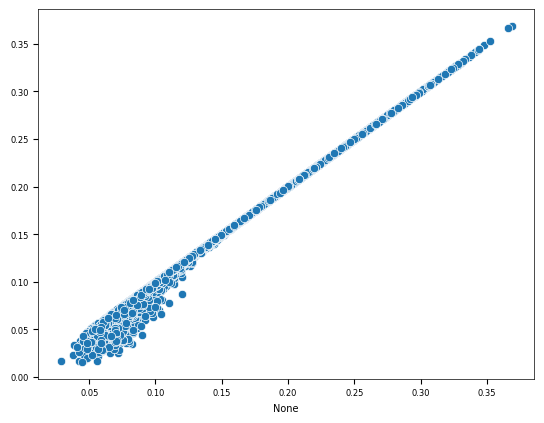

In [219]:
plt.figure()
sns.scatterplot(x = output.detach(),y = msd_data)

In [224]:
X_input = X_pre_pca

In [225]:
msd_data = output.detach().numpy()

In [226]:
X_input.shape

(11268, 200)

In [232]:
\

tensor([1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000])

In [246]:
def fsecond(t):
    return torch.sigmoid(t)*(1-torch.sigmoid(t))

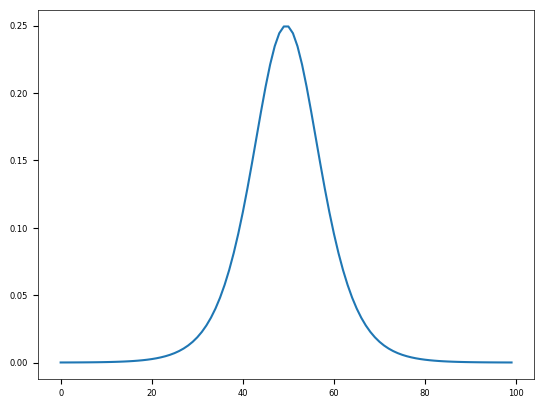

In [248]:
plt.figure()
plt.plot(fsecond(torch.linspace(-10,10,100)).numpy())